In [1]:
"""Educational tabular REINFORCE, synchronous one-step A2C, and PPO-Clip."""
from dataclasses import dataclass, replace, asdict
import time
import numpy as np
import gymnasium as gym

SHAPE = (32, 11, 2)
def idx(s): return tuple(map(int, s))

def softmax(x):
    z = x - np.max(x, axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

def ppo_coefficient(ratio, advantage, clip):
    """Derivative multiplier on grad log pi, away from clipping boundaries."""
    active = np.where(advantage >= 0, ratio <= 1 + clip, ratio >= 1 - clip)
    return ratio * advantage * active

@dataclass(frozen=True)
class Settings:
    episodes: int = 10_000
    actor_lr: float = .02
    critic_lr: float = .03
    gamma: float = 1.
    temperature: float = 1.
    entropy_coef: float = .001
    batch_episodes: int = 64
    reinforce_baseline: bool = False
    gae_lambda: float = .95
    clip_ratio: float = .2
    ppo_epochs: int = 4
    minibatch_size: int = 64
    normalize_advantage: bool = False
    seed: int = 42
    natural: bool = False
    sab: bool = False

    def __post_init__(self):
        for key in ('episodes','batch_episodes','ppo_epochs','minibatch_size'):
            if not isinstance(getattr(self,key),int) or getattr(self,key)<1:
                raise ValueError(key+' must be a positive integer')
        vals=[self.actor_lr,self.critic_lr,self.gamma,self.temperature,self.entropy_coef,self.gae_lambda,self.clip_ratio]
        if not np.isfinite(vals).all(): raise ValueError('Settings must be finite')
        if min(self.actor_lr,self.critic_lr,self.temperature)<=0 or self.entropy_coef<0:
            raise ValueError('Learning rates/temperature must be positive; entropy nonnegative')
        if not (0<=self.gamma<=1 and 0<=self.gae_lambda<=1 and 0<self.clip_ratio<1):
            raise ValueError('gamma/lambda must be in [0,1], clip_ratio in (0,1)')

class Adam:
    def __init__(self, shape):
        self.m=np.zeros(shape); self.v=np.zeros(shape); self.t=0
    def ascend(self, params, grad, lr):
        self.t+=1
        self.m=.9*self.m+.1*grad; self.v=.999*self.v+.001*grad**2
        params += lr*(self.m/(1-.9**self.t))/(np.sqrt(self.v/(1-.999**self.t))+1e-8)

class Agent:
    def __init__(self, algorithm='reinforce', settings=None):
        algorithm=algorithm.lower()
        if algorithm not in ('reinforce','a2c','ppo'): raise ValueError('Use reinforce, a2c, or ppo')
        self.algorithm=algorithm; self.settings=settings or Settings()
        self.logits=np.zeros(SHAPE+(2,)); self.values=np.zeros(SHAPE)
        self.actor_opt=Adam(self.logits.shape); self.critic_opt=Adam(SHAPE)
        self.rng=np.random.default_rng(self.settings.seed)
        self.rewards=[]; self.transitions=0; self.updates=[]; self.train_calls=0; self.seconds=0.

    def probabilities(self,state):
        return softmax(self.logits[idx(state)]/self.settings.temperature)
    def _env(self):
        c=self.settings
        return gym.make('Blackjack-v1',natural=c.natural,sab=c.sab)

    def _collect(self, env, n, first_seed=None):
        rows=[]; rewards=[]
        for ep in range(n):
            s,_=env.reset(seed=first_seed if ep==0 else None)
            trajectory=[]; total=0.
            while True:
                p=self.probabilities(s); a=int(self.rng.choice(2,p=p))
                ns,r,term,trunc,_=env.step(a)
                if trunc and not term:
                    raise RuntimeError('This teaching API expects natural episodic terminations')
                trajectory.append(dict(state=idx(s),action=a,reward=r,next_state=idx(ns),
                                       terminal=term,old_p=p.copy(),old_v=float(self.values[idx(s)])))
                total+=r; s=ns
                if term or trunc: break
            G=0.; gae=0.
            for t in reversed(range(len(trajectory))):
                row=trajectory[t]
                next_v=0. if row['terminal'] else float(self.values[row['next_state']])
                delta=row['reward']+self.settings.gamma*next_v-row['old_v']
                G=row['reward']+self.settings.gamma*G
                gae=delta+self.settings.gamma*self.settings.gae_lambda*gae
                row.update(time=t,mc_return=G,td_advantage=delta,gae=gae,
                           td_target=row['reward']+self.settings.gamma*next_v)
            rows.extend(trajectory); rewards.append(total)
        return rows,rewards

    def _targets(self, rows):
        if self.algorithm=='reinforce':
            adv=np.array([r['mc_return']-(r['old_v'] if self.settings.reinforce_baseline else 0.) for r in rows])
            targets=np.array([r['mc_return'] for r in rows])
            # Explicit discounted start-state objective weighting for REINFORCE.
            adv*=np.array([self.settings.gamma**r['time'] for r in rows])
        elif self.algorithm=='a2c':
            adv=np.array([r['td_advantage'] for r in rows]); targets=np.array([r['td_target'] for r in rows])
        else:
            adv=np.array([r['gae'] for r in rows]); targets=adv+np.array([r['old_v'] for r in rows])
        if self.settings.normalize_advantage and len(adv)>1:
            adv=(adv-adv.mean())/(adv.std()+1e-8)
        return adv,targets

    def _update(self, rows):
        c=self.settings; adv,targets=self._targets(rows)
        states=tuple(np.array([r['state'] for r in rows]).T)
        actions=np.array([r['action'] for r in rows]); old=np.array([r['old_p'] for r in rows])
        epochs=c.ppo_epochs if self.algorithm=='ppo' else 1
        for epoch in range(epochs):
            order=self.rng.permutation(len(rows)) if self.algorithm=='ppo' else np.arange(len(rows))
            size=c.minibatch_size if self.algorithm=='ppo' else len(rows)
            for start in range(0,len(rows),size):
                ix=order[start:start+size]; st=tuple(x[ix] for x in states); ac=actions[ix]
                p=softmax(self.logits[st]/c.temperature)
                ratio=p[np.arange(len(ix)),ac]/old[ix,ac]
                coeff=ppo_coefficient(ratio,adv[ix],c.clip_ratio) if self.algorithm=='ppo' else adv[ix]
                score=-p.copy(); score[np.arange(len(ix)),ac]+=1.
                logp=np.log(np.maximum(p,1e-300)); entropy=-(p*logp).sum(axis=1)
                grad=(coeff[:,None]*score-c.entropy_coef*p*(logp+entropy[:,None]))/c.temperature
                actor_grad=np.zeros_like(self.logits)
                np.add.at(actor_grad,st,grad/len(ix))
                self.actor_opt.ascend(self.logits,actor_grad,c.actor_lr)
                if self.algorithm!='reinforce' or c.reinforce_baseline:
                    vg=np.zeros_like(self.values)
                    np.add.at(vg,st,(targets[ix]-self.values[st])/len(ix))
                    self.critic_opt.ascend(self.values,vg,c.critic_lr)
        new=softmax(self.logits[states]/c.temperature)
        ratios=new[np.arange(len(rows)),actions]/old[np.arange(len(rows)),actions]
        kl=float(np.mean(np.sum(old*(np.log(np.maximum(old,1e-300))-np.log(np.maximum(new,1e-300))),axis=1)))
        self.updates.append(dict(episodes=len(self.rewards),transitions=self.transitions,
            entropy=float(np.mean(-np.sum(new*np.log(np.maximum(new,1e-300)),axis=1))),
            kl=kl,clip_fraction=float(np.mean(np.abs(ratios-1)>c.clip_ratio)) if self.algorithm=='ppo' else float('nan'),
            actor_steps=epochs*int(np.ceil(len(rows)/c.minibatch_size)) if self.algorithm=='ppo' else 1,
            advantage_std=float(adv.std())))

    def train(self, episodes=None):
        n=self.settings.episodes if episodes is None else episodes
        if not isinstance(n,int) or n<1: raise ValueError('episodes must be a positive integer')
        env=self._env(); start=time.perf_counter(); done=0
        try:
            while done<n:
                batch=min(self.settings.batch_episodes,n-done)
                rows,rewards=self._collect(env,batch,self.settings.seed+self.train_calls if done==0 else None)
                self.rewards.extend(rewards); self.transitions+=len(rows); self._update(rows); done+=batch
        finally: env.close()
        self.seconds+=time.perf_counter()-start; self.train_calls+=1
        return self

    def evaluate(self,episodes=10_000,seed=100_042,deterministic=False):
        if not isinstance(episodes,int) or episodes<1: raise ValueError('episodes must be positive integer')
        env=self._env(); rng=np.random.default_rng(seed); outcomes=[]
        try:
            for ep in range(episodes):
                s,_=env.reset(seed=seed if ep==0 else None); total=0.
                while True:
                    p=self.probabilities(s); a=int(p.argmax()) if deterministic else int(rng.choice(2,p=p))
                    s,r,term,trunc,_=env.step(a); total+=r
                    if term or trunc: break
                outcomes.append(total)
        finally: env.close()
        r=np.array(outcomes)
        wins, losses, draws = int((r>0).sum()), int((r<0).sum()), int((r==0).sum())
        return dict(algorithm=self.algorithm,episodes=episodes,deterministic=deterministic,
            wins=wins, losses=losses, draws=draws,
            win_loss_ratio=(wins/losses if losses else (float('inf') if wins else float('nan'))),
            mean_reward=float(r.mean()),standard_error=float(r.std(ddof=1)/np.sqrt(episodes)) if episodes>1 else float('nan'),
            win_rate=float((r>0).mean()),draw_rate=float((r==0).mean()),loss_rate=float((r<0).mean()),
            training_episodes=len(self.rewards),training_transitions=self.transitions,training_seconds=self.seconds,
            actor_steps=sum(x['actor_steps'] for x in self.updates))

    def explain_update(self,seed=123):
        """Collect one game with temporary RNG; inspect frozen targets without learning."""
        env=self._env(); old_rng=self.rng; self.rng=np.random.default_rng(seed)
        try: rows,_=self._collect(env,1,seed)
        finally: env.close(); self.rng=old_rng
        advantages,targets=self._targets(rows)
        return [dict(state=r['state'],action=r['action'],reward=r['reward'],value=r['old_v'],
                     mc_return=r['mc_return'],td_advantage=r['td_advantage'],gae=r['gae'],
                     used_advantage=float(a),critic_target=float(t),old_action_probability=float(r['old_p'][r['action']]))
                for r,a,t in zip(rows,advantages,targets)]

    def watch(self,episodes=3,seed=123,deterministic=True):
        env=self._env(); rng=np.random.default_rng(seed); traces=[]
        try:
            for ep in range(episodes):
                s,_=env.reset(seed=seed+ep); trace=[]
                while True:
                    p=self.probabilities(s); a=int(p.argmax()) if deterministic else int(rng.choice(2,p=p))
                    ns,r,term,trunc,_=env.step(a)
                    row=dict(state=s,probabilities=p.tolist(),action=a,reward=r)
                    print(row); trace.append(row); s=ns
                    if term or trunc: break
                traces.append(trace)
        finally: env.close()
        return traces


def build_agent(algorithm='reinforce', **settings): return Agent(algorithm,Settings(**settings))

def compare_agents(episodes=10_000,seeds=(42,),evaluation_episodes=10_000,overrides=None,**shared):
    """Equal game budgets, independent models. Returns agents keyed by (algorithm,seed), rows."""
    agents={}; results=[]
    for seed in seeds:
        for algorithm in ('reinforce','a2c','ppo'):
            params=dict(shared); params.update((overrides or {}).get(algorithm,{}))
            params.update(episodes=episodes,seed=seed)
            a=build_agent(algorithm,**params).train()
            agents[(algorithm,seed)]=a
            for deterministic in (False,True):
                row=a.evaluate(evaluation_episodes,deterministic=deterministic)
                row['seed']=seed; row['settings']=asdict(a.settings); results.append(row)
    return agents,results

def plot_learning(agents,window=500,x_axis='episodes'):
    import matplotlib.pyplot as plt
    if x_axis not in ('episodes','transitions'): raise ValueError('Use episodes or transitions')
    fig,ax=plt.subplots(figsize=(9,4))
    for key,a in agents.items():
        w=min(window,len(a.rewards))
        if w<1: raise ValueError('Train agents first and use positive window')
        y=np.convolve(a.rewards,np.ones(w)/w,'valid'); x=np.arange(w,len(a.rewards)+1)
        if x_axis=='transitions':
            # Map game counts to observed transition counts at batch boundaries.
            x=np.interp(x,[0]+[u['episodes'] for u in a.updates],[0]+[u['transitions'] for u in a.updates])
        ax.plot(x,y,label=str(key))
    ax.set(xlabel=x_axis+' (batch-interpolated for transitions)' if x_axis=='transitions' else 'Training games',ylabel='Rolling mean reward')
    ax.legend(); ax.grid(alpha=.3); fig.tight_layout(); return fig

def plot_policies(agents,usable_ace=False):
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(1,len(agents),figsize=(4*len(agents),4),squeeze=False,layout='constrained')
    for (key,a),ax in zip(agents.items(),axes[0]):
        data=[[a.probabilities((s,d,usable_ace))[1] for d in range(1,11)] for s in range(12,22)]
        im=ax.imshow(data,origin='lower',extent=(.5,10.5,11.5,21.5),vmin=0,vmax=1,aspect='auto')
        ax.set(title=str(key),xlabel='Dealer card (1=ace)',ylabel='Player total')
    fig.colorbar(im,ax=list(axes[0]),label='P(HIT)'); return fig

def plot_diagnostics(agent):
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(1,3,figsize=(12,3),layout='constrained')
    for ax,metric in zip(axes,('entropy','kl','clip_fraction')):
        ax.plot([u['episodes'] for u in agent.updates],[u[metric] for u in agent.updates])
        ax.set(title=metric,xlabel='Training games')
    return fig

def plot_ppo_objective(clip_ratio=.2):
    import matplotlib.pyplot as plt
    ratio=np.linspace(.4,1.6,500); fig,axes=plt.subplots(1,2,figsize=(10,3),layout='constrained')
    for advantage,ax in zip((1.,-1.),axes):
        ax.plot(ratio,ratio*advantage,'--',label='Unclipped')
        ax.plot(ratio,np.minimum(ratio*advantage,np.clip(ratio,1-clip_ratio,1+clip_ratio)*advantage),label='PPO objective')
        ax.axvline(1-clip_ratio,color='grey',alpha=.4); ax.axvline(1+clip_ratio,color='grey',alpha=.4)
        ax.set(title=f'Advantage = {advantage:+g}',xlabel='New / old action probability',ylabel='Objective'); ax.legend()
    return fig


def plot_outcomes(result):
    """Visualize an evaluation result without running another evaluation."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 3))
    counts = [result['wins'], result['draws'], result['losses']]
    bars = ax.bar(['Wins', 'Draws', 'Losses'], counts,
                  color=['#32936f', '#999999', '#d95d39'])
    ax.bar_label(bars, labels=[f'{v:,} ({v/result["episodes"]:.1%})' for v in counts])
    ax.set_ylim(0, max(1, max(counts))*1.2)
    ratio = result['win_loss_ratio']
    text = 'undefined (no wins or losses)' if np.isnan(ratio) else ('infinite (no losses)' if np.isinf(ratio) else f'{ratio:.3f}')
    mode = 'greedy' if result['deterministic'] else 'stochastic'
    ax.set(title=f'{result["algorithm"].upper()} ({mode}) — win/loss ratio: {text}', ylabel='Evaluation games')
    fig.tight_layout()
    return fig


def show_agent_report(agent, evaluation_episodes=10_000, window=1_000):
    """Evaluation, win/loss plots, learning curves, policies, and diagnostics."""
    import matplotlib.pyplot as plt
    name = agent.algorithm.upper()
    results = []
    for deterministic in (False, True):
        result = agent.evaluate(evaluation_episodes, deterministic=deterministic)
        results.append(result)
        print(result)
        plot_outcomes(result)
        plt.show()
    for axis in ('episodes', 'transitions'):
        plot_learning({name: agent}, window=window, x_axis=axis)
        plt.show()
    for ace in (False, True):
        fig = plot_policies({name: agent}, usable_ace=ace)
        fig.suptitle(f'{name} — usable ace: {ace}')
        plt.show()
    fig = plot_diagnostics(agent)
    if agent.algorithm != 'ppo':
        ax = fig.axes[2]
        ax.set_title('Clipping: not applicable')
        ax.text(.5, .5, 'This algorithm does not use clipping',
                ha='center', va='center', transform=ax.transAxes)
    plt.show()
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot([u['episodes'] for u in agent.updates], [u['advantage_std'] for u in agent.updates])
    ax.set(title=f'{name} — within-batch learning-signal variation',
           xlabel='Training games', ylabel='Standard deviation')
    fig.tight_layout()
    plt.show()
    if agent.algorithm != 'reinforce' or agent.settings.reinforce_baseline:
        fig, axes = plt.subplots(1, 2, figsize=(10,4), layout='constrained')
        for ace, ax in zip((False,True),axes):
            im = ax.imshow(agent.values[12:22,1:11,int(ace)],origin='lower',
                           extent=(.5,10.5,11.5,21.5),vmin=-1,vmax=1,aspect='auto',cmap='coolwarm')
            ax.set(title=f'Usable ace: {ace}',xlabel='Dealer card (1=ace)',ylabel='Player total')
        fig.colorbar(im,ax=list(axes),label='Estimated V(s)')
        fig.suptitle(f'{name} — critic values')
        plt.show()
    if agent.algorithm == 'ppo':
        plot_ppo_objective(agent.settings.clip_ratio)
        plt.show()
    return results


{'algorithm': 'reinforce', 'episodes': 10000, 'deterministic': False, 'wins': 4293, 'losses': 4833, 'draws': 874, 'win_loss_ratio': 0.888268156424581, 'mean_reward': -0.054, 'standard_error': 0.009538212502863153, 'win_rate': 0.4293, 'draw_rate': 0.0874, 'loss_rate': 0.4833, 'training_episodes': 300000, 'training_transitions': 430963, 'training_seconds': 61.358370399917476, 'actor_steps': 2344}


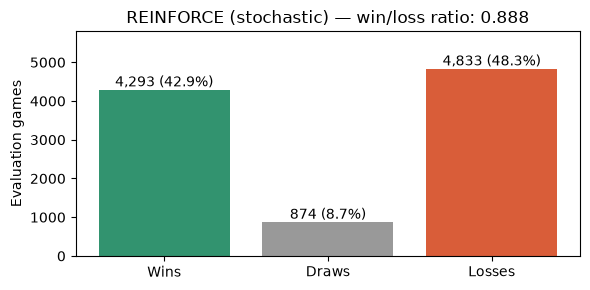

{'algorithm': 'reinforce', 'episodes': 10000, 'deterministic': True, 'wins': 4376, 'losses': 4734, 'draws': 890, 'win_loss_ratio': 0.9243768483312209, 'mean_reward': -0.0358, 'standard_error': 0.009538392636781596, 'win_rate': 0.4376, 'draw_rate': 0.089, 'loss_rate': 0.4734, 'training_episodes': 300000, 'training_transitions': 430963, 'training_seconds': 61.358370399917476, 'actor_steps': 2344}


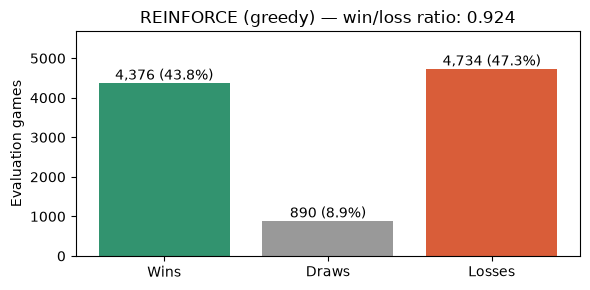

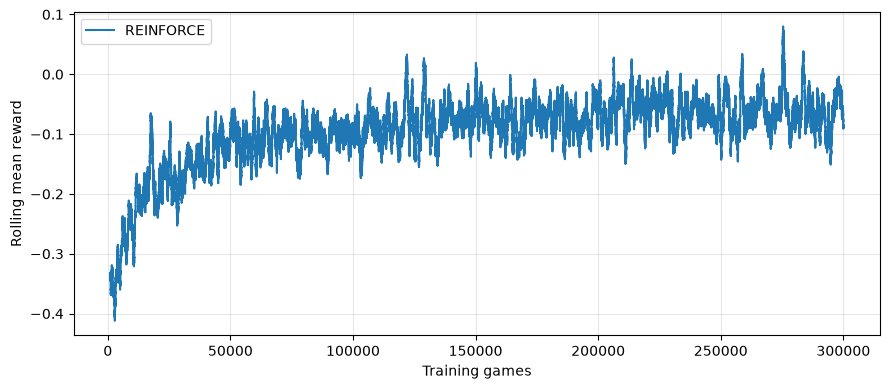

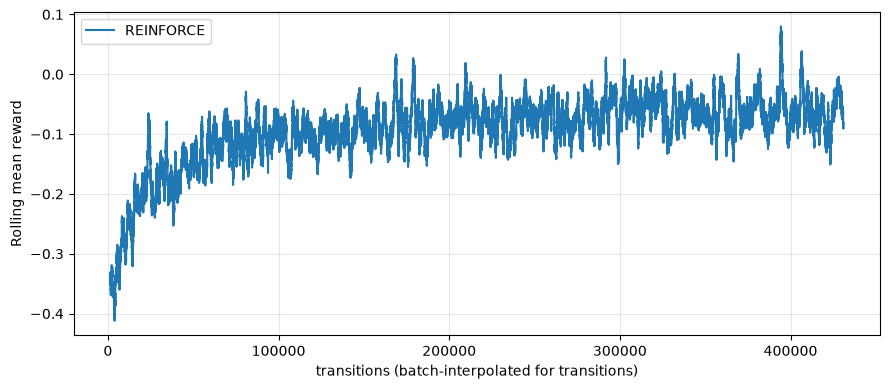

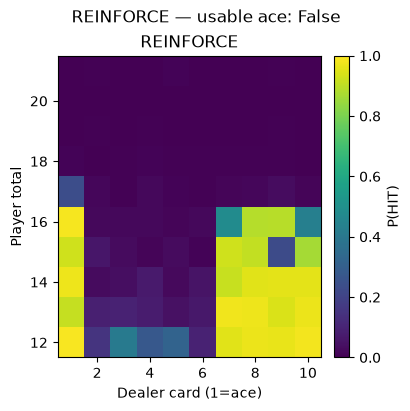

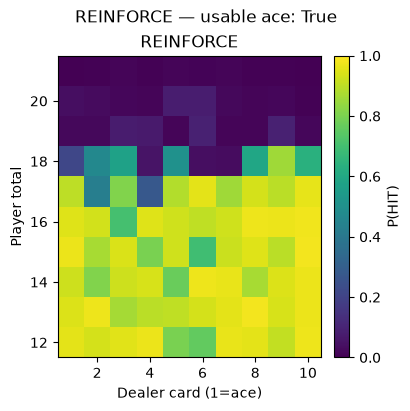

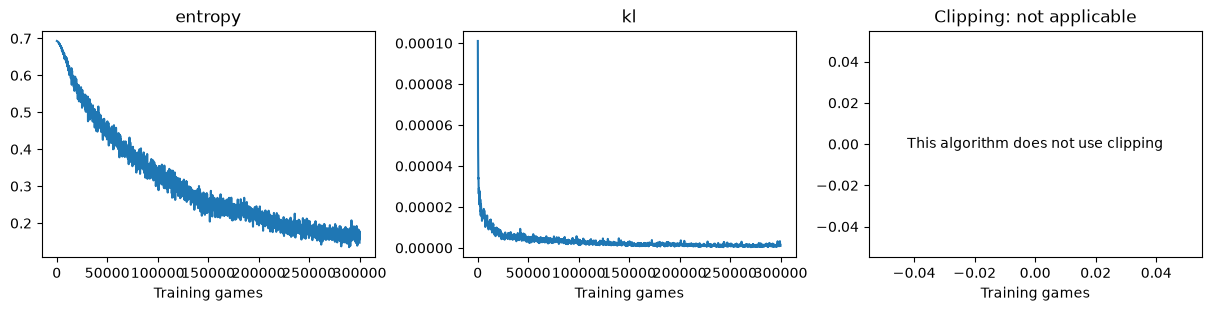

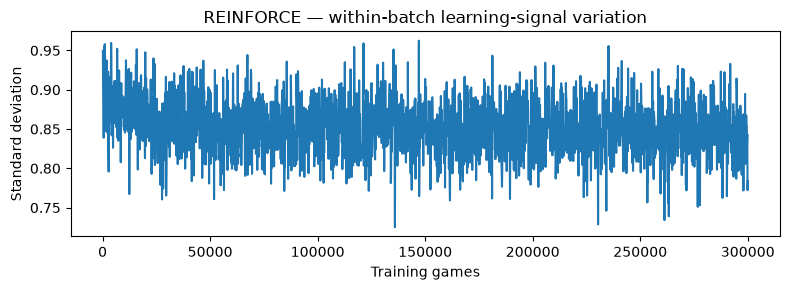

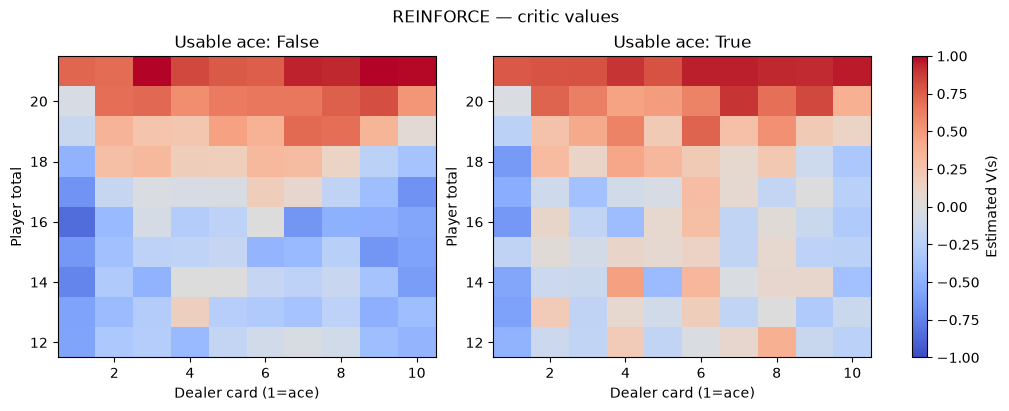

In [25]:
import matplotlib.pyplot as plt

reinforce_agent = build_agent(
    algorithm="reinforce",
    episodes=300_000,
    actor_lr=0.015,
    #critic_lr=0.03,
    gamma=1.0,
    temperature=1.0,
    entropy_coef=0.0001,
    reinforce_baseline=True,
    batch_episodes=128,
    #gae_lambda=0.95,
    #clip_ratio=0.2,
    #ppo_epochs=4,
    #minibatch_size=64,
    seed=42,
)

reinforce_agent.train()


reinforce_results = show_agent_report(reinforce_agent)

{'algorithm': 'ppo', 'episodes': 10000, 'deterministic': False, 'wins': 4245, 'losses': 4898, 'draws': 857, 'win_loss_ratio': 0.8666802776643528, 'mean_reward': -0.0653, 'standard_error': 0.009540057246643068, 'win_rate': 0.4245, 'draw_rate': 0.0857, 'loss_rate': 0.4898, 'training_episodes': 100000, 'training_transitions': 148776, 'training_seconds': 19.117064799997024, 'actor_steps': 10596}


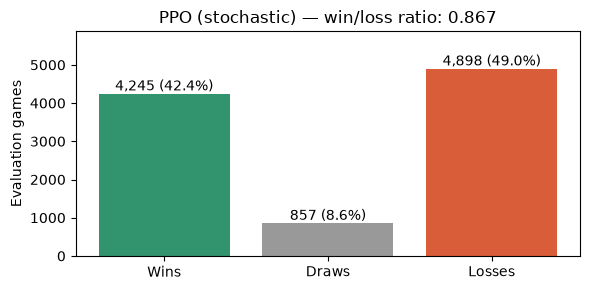

{'algorithm': 'ppo', 'episodes': 10000, 'deterministic': True, 'wins': 4272, 'losses': 4876, 'draws': 852, 'win_loss_ratio': 0.8761279737489746, 'mean_reward': -0.0604, 'standard_error': 0.009545904694142036, 'win_rate': 0.4272, 'draw_rate': 0.0852, 'loss_rate': 0.4876, 'training_episodes': 100000, 'training_transitions': 148776, 'training_seconds': 19.117064799997024, 'actor_steps': 10596}


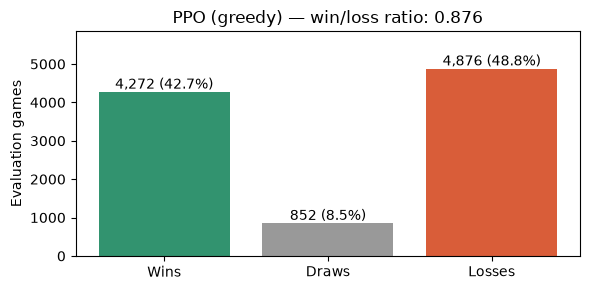

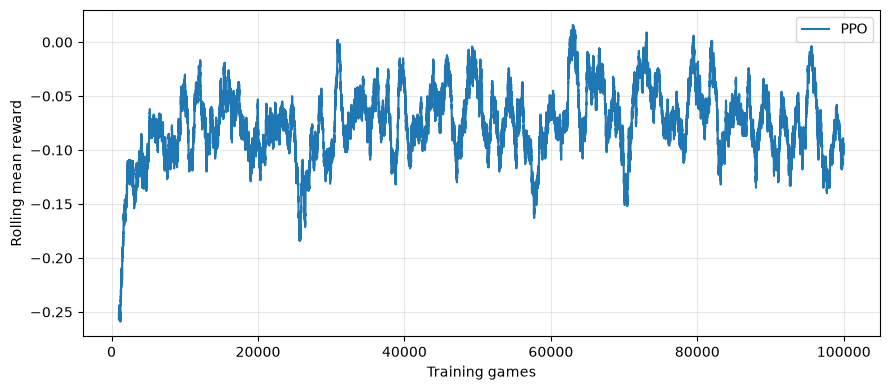

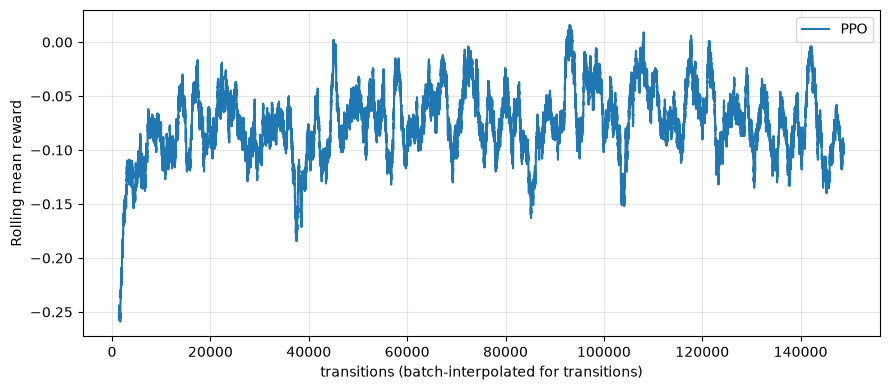

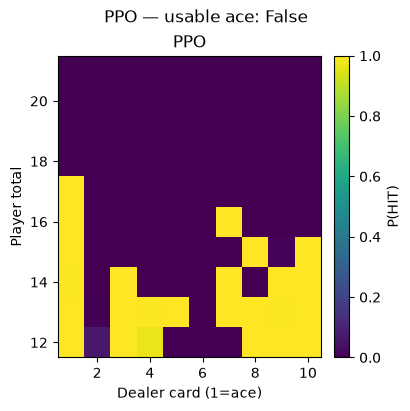

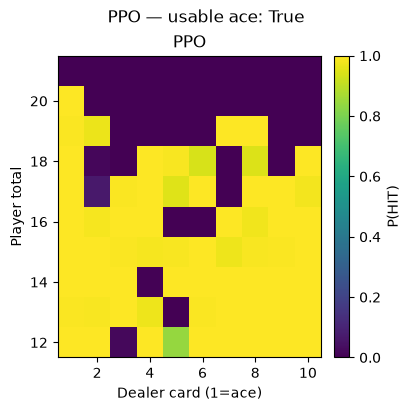

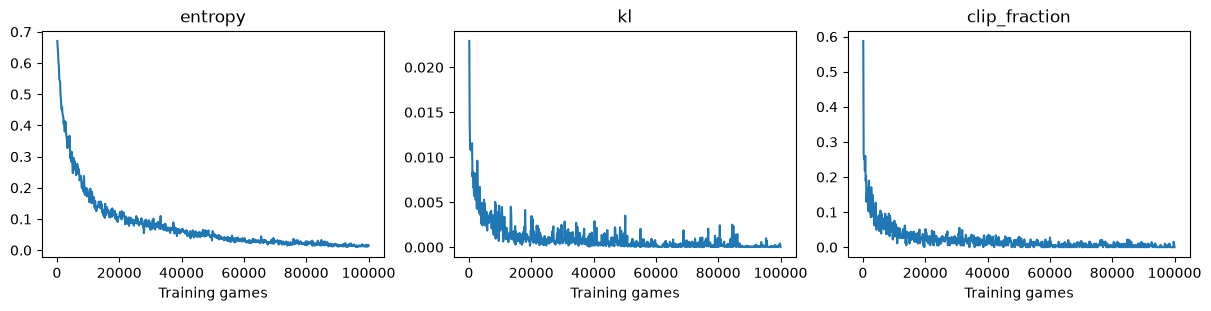

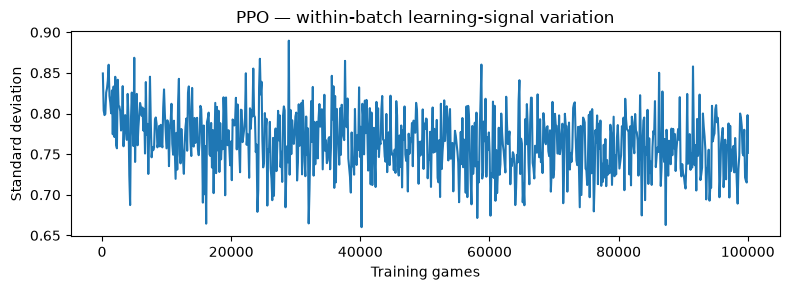

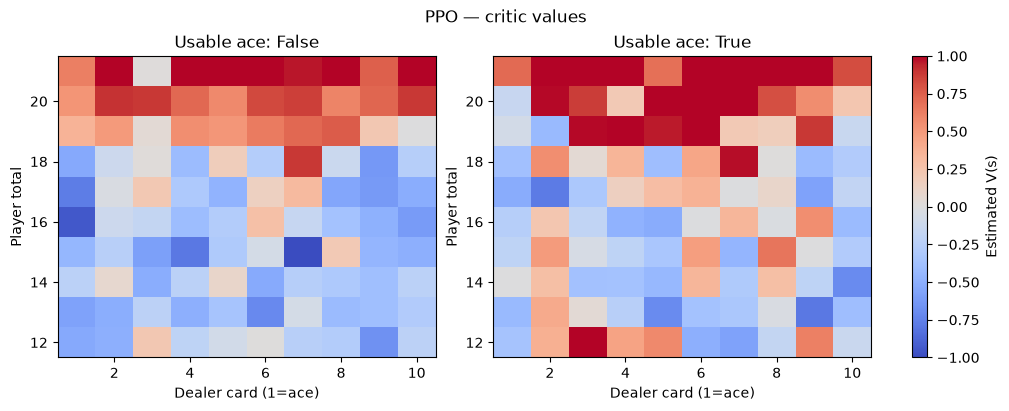

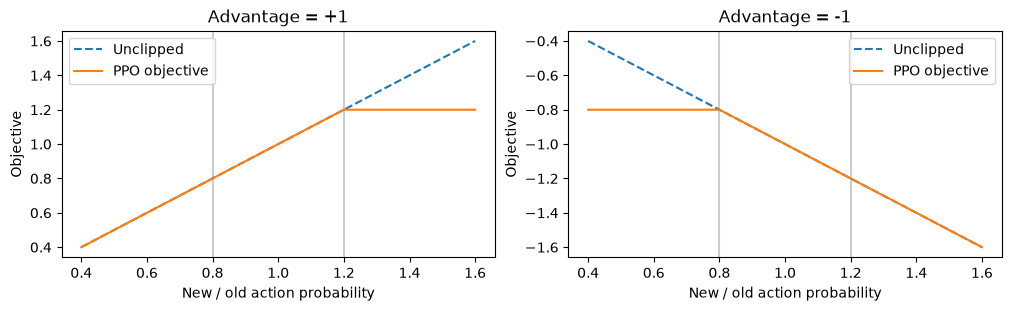

In [ ]:
ppo_agent = build_agent(
    algorithm="ppo",
    episodes=100_000, #optimize
    actor_lr=0.02, #optimize
    critic_lr=0.02, #optimize
    gamma=0.5, #optimize
    temperature=1.0,
    entropy_coef=0.0001,
    batch_episodes=128,
    gae_lambda=0.95,
    clip_ratio=0.2,
    ppo_epochs=4,
    minibatch_size=64,
    seed=42,
)

ppo_agent.train()

    
ppo_results = show_agent_report(ppo_agent)

In [3]:
agents, results = compare_agents(
    episodes=10_000,
    seeds=(42,),             # Try (42, 43, 44) for repeated runs.
    evaluation_episodes=5_000,
    actor_lr=0.02,
    critic_lr=0.03,
    gamma=1.0,
    entropy_coef=0.001,
    batch_episodes=64,
    overrides={
        "reinforce": {"reinforce_baseline": False},
        "a2c": {},
        "ppo": {"clip_ratio": 0.2, "ppo_epochs": 4, "gae_lambda": 0.95},
    },
)
for row in results:
    print(row["algorithm"], "seed", row["seed"],
          "greedy" if row["deterministic"] else "stochastic",
          "mean", round(row["mean_reward"], 4),
          "SE", round(row["standard_error"], 4),
          "transitions", row["training_transitions"],
          "actor steps", row["actor_steps"],
          "seconds", round(row["training_seconds"], 1))

reinforce seed 42 stochastic mean -0.1874 SE 0.0134 transitions 13533 actor steps 157 seconds 2.0
reinforce seed 42 greedy mean -0.0896 SE 0.0135 transitions 13533 actor steps 157 seconds 2.0
a2c seed 42 stochastic mean -0.165 SE 0.0134 transitions 13533 actor steps 157 seconds 2.1
a2c seed 42 greedy mean -0.0854 SE 0.0135 transitions 13533 actor steps 157 seconds 2.1
ppo seed 42 stochastic mean -0.0934 SE 0.0135 transitions 13962 actor steps 1252 seconds 2.3
ppo seed 42 greedy mean -0.0814 SE 0.0135 transitions 13962 actor steps 1252 seconds 2.3


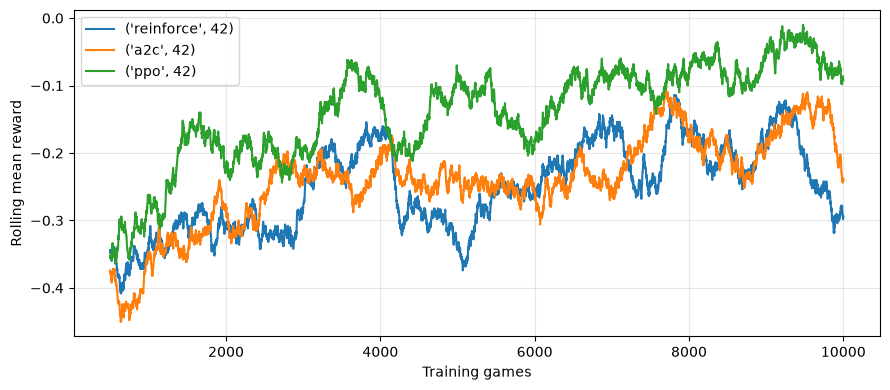

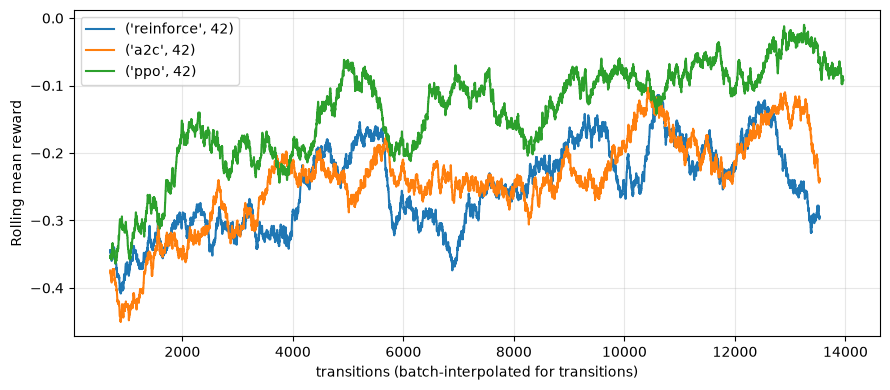

In [4]:
import matplotlib.pyplot as plt
plot_learning(agents, window=500)
plt.show()
plot_learning(agents, window=500, x_axis="transitions")
plt.show()

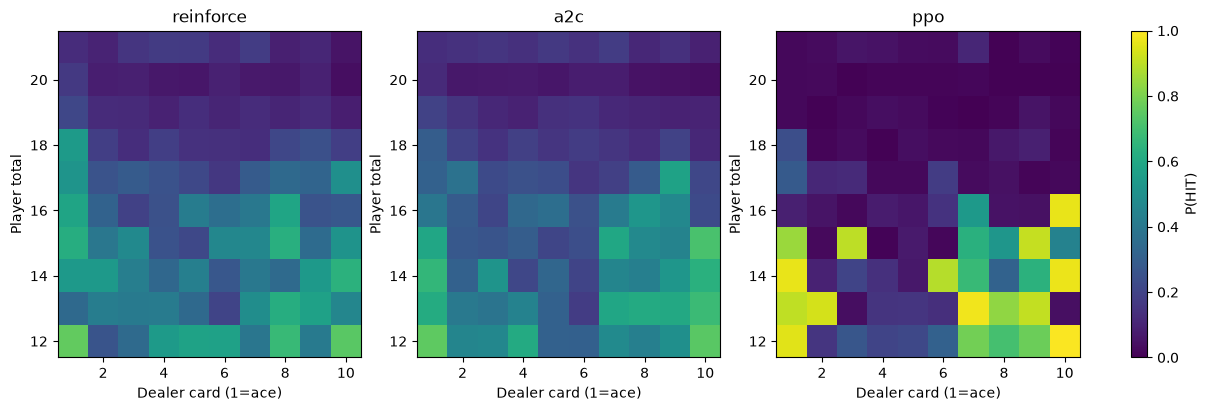

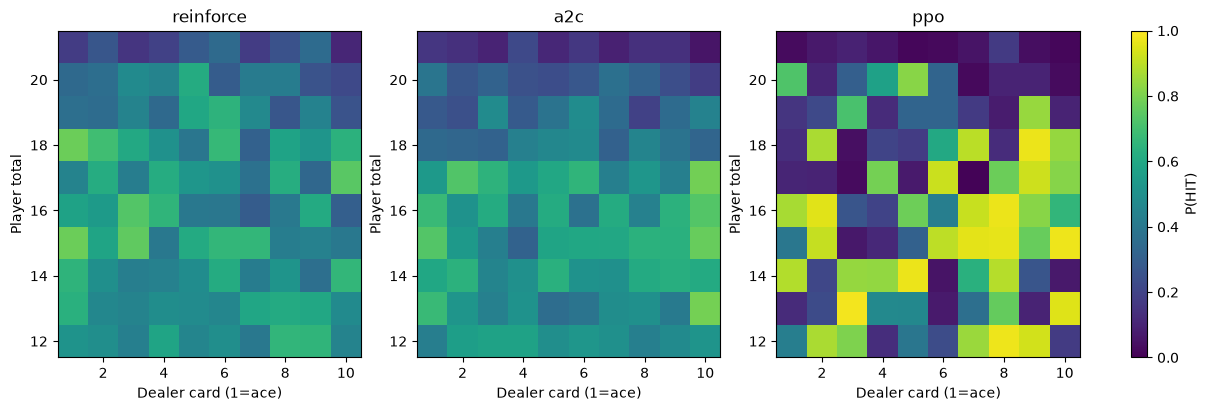

In [5]:
selected = {name: agents[(name, 42)] for name in ("reinforce", "a2c", "ppo")}
plot_policies(selected, usable_ace=False)
plt.show()
plot_policies(selected, usable_ace=True)
plt.show()

In [6]:
import numpy as np
import matplotlib.pyplot as plt

EVALUATION_EPISODES = 10_000
DETERMINISTIC = False  # True = greedy; False = sample learned policy

agents_to_compare = {
    "REINFORCE": reinforce_agent,
    "A2C": a2c_agent,
    "PPO": ppo_agent,
}

comparison = {
    name: agent.evaluate(
        episodes=EVALUATION_EPISODES,
        seed=100_042,
        deterministic=DETERMINISTIC,
    )
    for name, agent in agents_to_compare.items()
}

# Print outcome counts and ratios.
print(f"{'Agent':<12} {'Wins':>7} {'Losses':>7} {'Draws':>7} {'W/L ratio':>12}")
print("-" * 50)

for name, result in comparison.items():
    print(
        f"{name:<12} "
        f"{result['wins']:>7} "
        f"{result['losses']:>7} "
        f"{result['draws']:>7} "
        f"{result['win_loss_ratio']:>12.3f}"
    )

# Compare ratios visually.
names = list(comparison)
ratios = [comparison[name]["win_loss_ratio"] for name in names]

# Infinite or undefined ratios cannot be represented as bar heights.
heights = [ratio if np.isfinite(ratio) else 0 for ratio in ratios]

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    names,
    heights,
    color=["steelblue", "darkorange", "seagreen"],
)

for bar, ratio in zip(bars, ratios):
    label = (
        "Undefined" if np.isnan(ratio)
        else "∞ (no losses)" if np.isinf(ratio)
        else f"{ratio:.3f}"
    )
    ax.annotate(
        label,
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
    )

ax.axhline(
    1.0,
    color="black",
    linestyle="--",
    label="Equal wins and losses",
)

ax.set_ylim(0, max(1.0, max(heights)) * 1.25)
ax.set_ylabel("Wins ÷ losses")
ax.set_title(
    "Blackjack win/loss ratio comparison — "
    + ("greedy policies" if DETERMINISTIC else "stochastic policies")
)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'reinforce_agent' is not defined